# Análisis integral de reseñas cinematográficas con Word2Vec
### BoW · TF-IDF · CBOW · Skip-Gram
**Proyecto académico de Big Data**    
**Datos:** 12.368 reseñas de películas  
**Modalidad:** Análisis reproducible en Jupyter Notebook

## 1. Objetivos y metodología
**Objetivo general:** analizar reseñas cinematográficas mediante representaciones de texto basadas en frecuencias, ponderaciones y vectores distribucionales.

**Objetivos específicos:** describir el conjunto de datos, verificar la correspondencia entre identificadores y artefactos, analizar BoW y TF-IDF, comparar CBOW y Skip-Gram, y evaluar exploratoriamente la similitud entre reseñas.

**Metodología:** carga → validación → análisis descriptivo → análisis léxico → modelos Word2Vec → comparación → conclusiones.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import load_npz
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
from gensim.models import Word2Vec

# Localiza el proyecto aunque Jupyter se inicie desde otra carpeta cercana.
def localizar_proyecto():
    bases = [Path.cwd(), Path.cwd().parent]
    try:
        bases += [Path(__file__).resolve().parent]
    except NameError:
        pass
    for base in bases:
        for candidata in [base, base / 'Proyecto_Word2Vec']:
            if (candidata / 'data' / 'resenas_mongodb.csv').exists() and (candidata / 'resultados').is_dir():
                return candidata.resolve()
    raise FileNotFoundError('No se encontró data/resenas_mongodb.csv. Coloque el notebook en la carpeta Proyecto_Word2Vec y ábralo desde allí.')

RAIZ = localizar_proyecto()
print('Proyecto:', RAIZ)
print('Python:', sys.version.split()[0])

Proyecto: C:\Users\marie\Downloads\Proyecto_Word2Vec_Con_Interpretaciones\Proyecto_Word2Vec
Python: 3.13.9


## 2. Carga de datos y archivos procesados
Los identificadores se leen como texto para conservar su formato original. Los archivos `.npz` contienen matrices dispersas y los `.csv.gz` contienen vectores por reseña.

In [2]:
df = pd.read_csv(RAIZ/'data'/'resenas_mongodb.csv', dtype={'id_resena':str}, low_memory=False)
ids = pd.read_csv(RAIZ/'resultados'/'ids_resenas.csv', dtype={'id_resena':str})
bow = load_npz(RAIZ/'resultados'/'bow.npz')
tfidf = load_npz(RAIZ/'resultados'/'tfidf.npz')
cbow = pd.read_csv(RAIZ/'resultados'/'vectores_cbow.csv.gz', dtype={'id_resena':str})
sg = pd.read_csv(RAIZ/'resultados'/'vectores_skip_gram.csv.gz', dtype={'id_resena':str})
vocab = pd.read_csv(RAIZ/'resultados'/'vocabulario.csv')
modelo_cbow = Word2Vec.load(str(RAIZ/'resultados'/'modelo_cbow.model'))
modelo_sg = Word2Vec.load(str(RAIZ/'resultados'/'modelo_skip_gram.model'))
print('Reseñas:',len(df),'| Columnas:',len(df.columns))
print('BoW:',bow.shape,'| TF-IDF:',tfidf.shape)
print('CBOW:',cbow.shape,'| Skip-Gram:',sg.shape)
display(df[['id_resena','titulo_obra','genero_principal','polaridad','calificacion']].head())

Reseñas: 12368 | Columnas: 24
BoW: (12368, 10000) | TF-IDF: (12368, 10000)
CBOW: (12368, 101) | Skip-Gram: (12368, 101)


,id_resena,titulo_obra,genero_principal,polaridad,calificacion
0,p1_1,NaN,Animación,positiva,10
1,p1_2,NaN,Comedia,intermedia,6
2,p1_3,NaN,Drama,positiva,7
3,p1_4,NaN,Terror,positiva,9
4,p1_5,NaN,Acción,positiva,7


## 3. Validación de integridad
Antes de interpretar cualquier resultado, comprobamos que cada fila de las matrices y vectores corresponde a la misma reseña original.

In [3]:
assert df.id_resena.notna().all() and df.id_resena.is_unique, 'Identificadores inválidos en el CSV'
assert len(df)==len(ids)==len(cbow)==len(sg)==bow.shape[0]==tfidf.shape[0]
assert df.id_resena.reset_index(drop=True).equals(ids.id_resena)
assert ids.id_resena.equals(cbow.id_resena) and ids.id_resena.equals(sg.id_resena)
assert bow.shape==tfidf.shape and bow.shape[1]==len(vocab)
assert cbow.shape[1]==sg.shape[1]
print('✓ Validación correcta: filas, identificadores, vocabulario y dimensiones coherentes.')
print('Textos vacíos:',df.texto_es.fillna('').str.strip().eq('').sum())
print('Duplicados de texto:',df.texto_es.fillna('').duplicated().sum())

✓ Validación correcta: filas, identificadores, vocabulario y dimensiones coherentes.
Textos vacíos: 0
Duplicados de texto: 16


## 4. Perfil general del conjunto de datos
Se examinan el origen, las categorías, las calificaciones y los valores faltantes. Las frecuencias describen esta colección, no necesariamente todas las reseñas cinematográficas.

In [4]:
display(df[['origen_texto','genero_principal','polaridad','calificacion','metricas.num_palabras']].describe(include='all').T)
faltantes = df.isna().sum().sort_values(ascending=False)
display(faltantes.head(12).rename('valores_faltantes').to_frame())

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
origen_texto,12368,2,traducido,6283,NaN,NaN,NaN,NaN,NaN,NaN,NaN
genero_principal,12368,5,Drama,2783,NaN,NaN,NaN,NaN,NaN,NaN,NaN
polaridad,12368,3,positiva,8484,NaN,NaN,NaN,NaN,NaN,NaN,NaN
calificacion,12368.0,NaN,NaN,NaN,7.234557,2.894671,1.0,6.0,8.0,10.0,10.0
metricas.num_palabras,12368.0,NaN,NaN,NaN,159.742804,236.88655,1.0,44.0,127.0,209.0,9233.0


,valores_faltantes
anio_estreno,6283
titulo_obra,6283
url_fuente,6283
anio_review,6085
movie_id,6085
texto_en,6085
is_spoiler,5205
metricas.ratio_verbos_sustantivos,126
calificacion,0
periodo,0


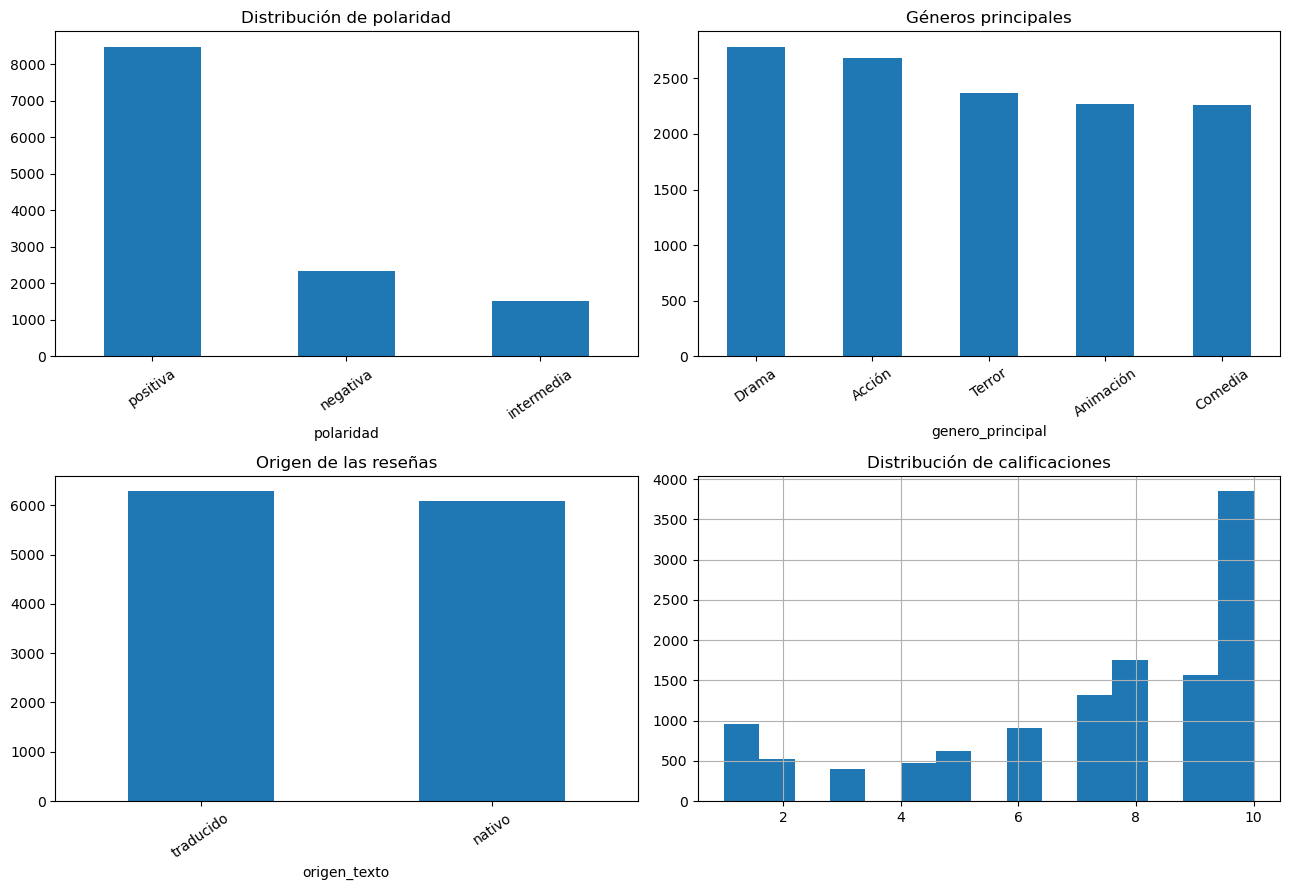

In [5]:
fig, axes = plt.subplots(2,2,figsize=(13,9))
for ax,col,titulo,top in [(axes[0,0],'polaridad','Distribución de polaridad',10),(axes[0,1],'genero_principal','Géneros principales',10),(axes[1,0],'origen_texto','Origen de las reseñas',10)]:
    df[col].fillna('Sin dato').astype(str).value_counts().head(top).plot.bar(ax=ax)
    ax.set_title(titulo);ax.tick_params(axis='x',rotation=35)
pd.to_numeric(df['calificacion'],errors='coerce').hist(bins=15,ax=axes[1,1]);axes[1,1].set_title('Distribución de calificaciones')
plt.tight_layout();plt.show()

### Interpretación del gráfico
### 1. Distribución de polaridad
Se observa un predominio de reseñas positivas, seguido de opiniones negativas e intermedias, lo que refleja una tendencia favorable hacia las películas analizadas.

### 2. Géneros principales
Drama y Acción son los géneros con mayor cantidad de reseñas, seguidos de Terror, Animación y Comedia, evidenciando una variedad de contenido cinematográfico.

### 3. Origen de las reseñas
Las reseñas traducidas y nativas presentan cantidades similares, lo que demuestra una distribución equilibrada entre ambos orígenes.

### 4. Distribución de calificaciones
La mayoría de las calificaciones se concentra entre 7 y 10, destacando la puntuación máxima. Esto confirma una tendencia hacia valoraciones positivas de las películas.


In [6]:
from IPython.display import Markdown, display
for col, titulo in [('polaridad','Polaridad'),('genero_principal','Géneros principales'),('origen_texto','Origen de las reseñas')]:
    conteos = df[col].fillna('Sin dato').astype(str).value_counts()
    if len(conteos):
        nombre, cantidad = str(conteos.index[0]), int(conteos.iloc[0])
        display(Markdown(f'**Interpretación — {titulo}:** La categoría más representada es **{nombre}**, con **{cantidad:,} reseñas** ({cantidad/len(df):.1%} del total). Esta distribución describe la composición de la muestra; no demuestra por sí sola el rendimiento de los modelos.'))
notas = pd.to_numeric(df['calificacion'], errors='coerce').dropna()
if len(notas):
    display(Markdown(f'**Interpretación — Calificaciones:** Se dispone de **{len(notas):,} calificaciones válidas**, con media **{notas.mean():.2f}** y mediana **{notas.median():.2f}**. La diferencia entre ambos valores ayuda a identificar asimetrías; el histograma permite observar la concentración de puntuaciones.'))
else:
    display(Markdown('**Interpretación — Calificaciones:** No hay calificaciones numéricas suficientes para describir esta distribución.'))

**Interpretación — Polaridad:** La categoría más representada es **positiva**, con **8,484 reseñas** (68.6% del total). Esta distribución describe la composición de la muestra; no demuestra por sí sola el rendimiento de los modelos.

**Interpretación — Géneros principales:** La categoría más representada es **Drama**, con **2,783 reseñas** (22.5% del total). Esta distribución describe la composición de la muestra; no demuestra por sí sola el rendimiento de los modelos.

**Interpretación — Origen de las reseñas:** La categoría más representada es **traducido**, con **6,283 reseñas** (50.8% del total). Esta distribución describe la composición de la muestra; no demuestra por sí sola el rendimiento de los modelos.

**Interpretación — Calificaciones:** Se dispone de **12,368 calificaciones válidas**, con media **7.23** y mediana **8.00**. La diferencia entre ambos valores ayuda a identificar asimetrías; el histograma permite observar la concentración de puntuaciones.

## 5. Longitud y características de los textos
La longitud influye en la cantidad de palabras disponibles para representar cada reseña. Una reseña corta puede producir un vector menos informativo.

Longitud (palabras):


,palabras
count,12368.000000
mean,159.742804
std,236.886550
min,1.000000
10%,22.000000
25%,44.000000
50%,127.000000
75%,209.000000
90%,320.000000
95%,384.000000


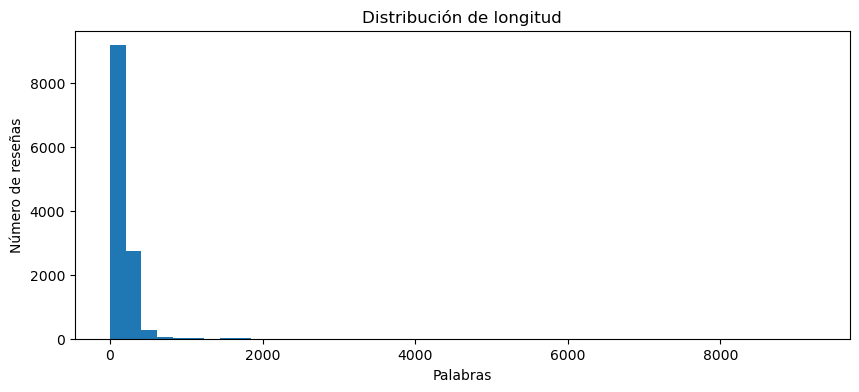

In [7]:
longitud = pd.to_numeric(df['metricas.num_palabras'],errors='coerce')
if longitud.notna().sum()==0:
    longitud = df.texto_es.fillna('').str.split().str.len()
print('Longitud (palabras):');display(longitud.describe(percentiles=[.1,.25,.5,.75,.9,.95]).to_frame('palabras'))
fig,ax=plt.subplots(figsize=(10,4));ax.hist(longitud.dropna(),bins=45);ax.set(xlabel='Palabras',ylabel='Número de reseñas',title='Distribución de longitud');plt.show()

In [8]:
from IPython.display import Markdown, display
l = longitud.dropna()
if len(l):
    display(Markdown(f'**Interpretación — Longitud de las reseñas:** La mediana es de **{l.median():.0f} palabras** y el promedio de **{l.mean():.1f}**. El 25 % de los textos tiene hasta **{l.quantile(.25):.0f} palabras**, mientras que el 75 % tiene hasta **{l.quantile(.75):.0f}**. La dispersión importa porque los textos más largos pueden aportar más contexto al modelo y los muy cortos pueden ofrecer señales limitadas.'))

**Interpretación — Longitud de las reseñas:** La mediana es de **127 palabras** y el promedio de **159.7**. El 25 % de los textos tiene hasta **44 palabras**, mientras que el 75 % tiene hasta **209**. La dispersión importa porque los textos más largos pueden aportar más contexto al modelo y los muy cortos pueden ofrecer señales limitadas.

## 6. BoW: bolsa de palabras
**Bag of Words** contabiliza las apariciones de términos. Conserva información de frecuencia, pero pierde el orden de las palabras y la relación contextual.

,termino,frecuencia
2423,de,106555
5401,la,71902
7638,que,70996
3234,en,43636
3132,el,40815
3450,es,36036
9482,una,30976
9481,un,29035
6973,película,28741
6490,no,26451


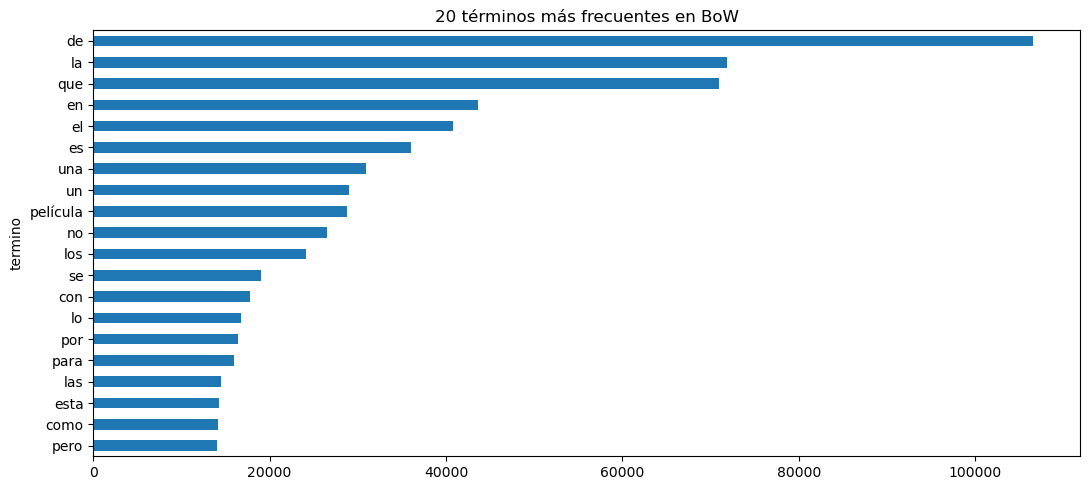

Proporción de elementos no nulos: 0.00843


In [9]:
frecuencias = np.asarray(bow.sum(axis=0)).ravel()
terminos = vocab['termino'].astype(str).to_numpy()
ranking = pd.DataFrame({'termino':terminos,'frecuencia':frecuencias}).sort_values('frecuencia',ascending=False)
display(ranking.head(20))
fig,ax=plt.subplots(figsize=(11,5));ranking.head(20).sort_values('frecuencia').plot.barh(x='termino',y='frecuencia',ax=ax,legend=False)
ax.set_title('20 términos más frecuentes en BoW');plt.tight_layout();plt.show()
print('Proporción de elementos no nulos:',round(bow.nnz/(bow.shape[0]*bow.shape[1]),5))

### Interpretación del gráfico
Las siguientes observaciones se calculan automáticamente con los resultados del archivo, para evitar conclusiones genéricas o cifras inventadas.


In [10]:
from IPython.display import Markdown, display
if len(ranking):
    top = ranking.iloc[0]
    display(Markdown(f'**Interpretación — Frecuencia BoW:** El término más frecuente es **{top["termino"]}**, con **{int(top["frecuencia"]):,} apariciones** en la matriz. Las barras muestran palabras dominantes por repetición; esta medida no indica por sí sola cuáles son más informativas o importantes para distinguir reseñas. La matriz contiene **{bow.nnz/(bow.shape[0]*bow.shape[1]):.2%}** de posiciones distintas de cero, lo que evidencia su carácter disperso.'))

**Interpretación — Frecuencia BoW:** El término más frecuente es **de**, con **106,555 apariciones** en la matriz. Las barras muestran palabras dominantes por repetición; esta medida no indica por sí sola cuáles son más informativas o importantes para distinguir reseñas. La matriz contiene **0.84%** de posiciones distintas de cero, lo que evidencia su carácter disperso.

## 7. TF-IDF: importancia relativa de términos
**TF-IDF** pondera los términos según su presencia en una reseña y su distribución en el corpus. Ayuda a destacar palabras relativamente distintivas, sin incorporar por sí mismo relaciones semánticas.

,termino,peso_medio
2423,de,0.150388
5401,la,0.107621
7638,que,0.105421
3234,en,0.069109
3132,el,0.065750
3450,es,0.064588
6973,película,0.057023
9482,una,0.055654
9481,un,0.051058
6490,no,0.050578


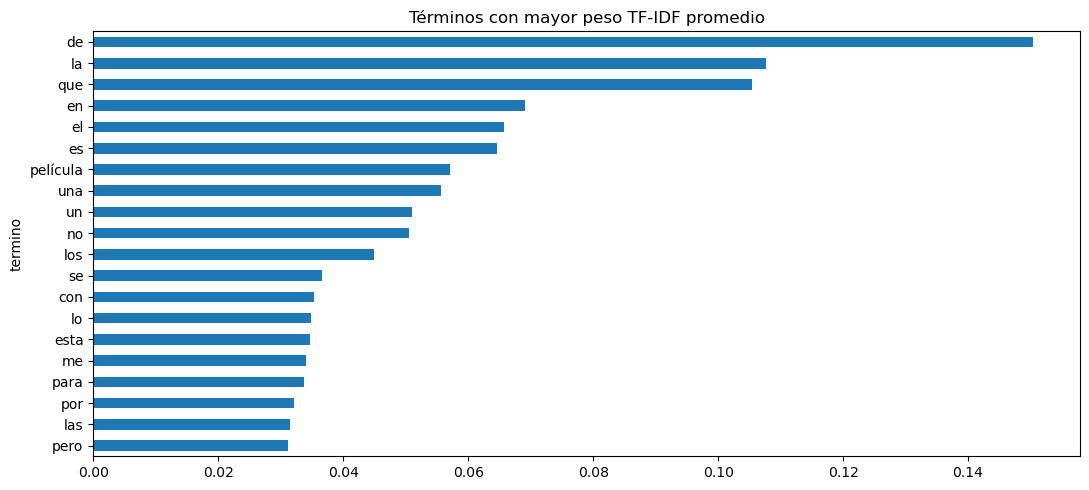

In [11]:
pesos = np.asarray(tfidf.mean(axis=0)).ravel()
ranking_tfidf = pd.DataFrame({'termino':terminos,'peso_medio':pesos}).sort_values('peso_medio',ascending=False)
display(ranking_tfidf.head(20))
fig,ax=plt.subplots(figsize=(11,5));ranking_tfidf.head(20).sort_values('peso_medio').plot.barh(x='termino',y='peso_medio',ax=ax,legend=False)
ax.set_title('Términos con mayor peso TF-IDF promedio');plt.tight_layout();plt.show()

In [12]:
from IPython.display import Markdown, display
if len(ranking_tfidf):
    top = ranking_tfidf.iloc[0]
    comunes = set(ranking.head(20)['termino']) & set(ranking_tfidf.head(20)['termino'])
    display(Markdown(f'**Interpretación — TF-IDF:** El término con mayor peso medio es **{top["termino"]}** (valor **{top["peso_medio"]:.4f}**). De los 20 términos principales, **{len(comunes)}** también aparecen en el ranking de BoW. TF-IDF pondera frecuencia y distribución entre documentos, por lo que su ranking no tiene por qué coincidir con el de conteos absolutos.'))

**Interpretación — TF-IDF:** El término con mayor peso medio es **de** (valor **0.1504**). De los 20 términos principales, **19** también aparecen en el ranking de BoW. TF-IDF pondera frecuencia y distribución entre documentos, por lo que su ranking no tiene por qué coincidir con el de conteos absolutos.

## 8. Comparación de BoW y TF-IDF por reseña
Para una reseña seleccionada se comparan los términos más repetidos con los de mayor ponderación. Los rankings no tienen por qué coincidir.

In [13]:
indice = 0
fila_bow=bow.getrow(indice).toarray().ravel();fila_tf=tfidf.getrow(indice).toarray().ravel()
comparacion=pd.DataFrame({'termino':terminos,'conteo_bow':fila_bow,'peso_tfidf':fila_tf})
print('ID:',df.iloc[indice].id_resena)
print('Términos frecuentes:');display(comparacion.nlargest(12,'conteo_bow'))
print('Términos relevantes según TF-IDF:');display(comparacion.nlargest(12,'peso_tfidf'))

ID: p1_1
Términos frecuentes:


,termino,conteo_bow,peso_tfidf
7638,que,7,0.191485
5401,la,6,0.159054
8403,se,5,0.182020
942,años,4,0.276223
4484,ha,3,0.187716
6973,película,3,0.093017
9634,ver,3,0.156283
2026,contigo,2,0.340072
3450,es,2,0.059957
3591,esta,2,0.076147


Términos relevantes según TF-IDF:


,termino,conteo_bow,peso_tfidf
2026,contigo,2,0.340072
942,años,4,0.276223
7639,queda,2,0.218703
7066,persona,2,0.197353
7638,que,7,0.191485
4484,ha,3,0.187716
734,arrastrada,1,0.187360
8403,se,5,0.182020
6334,mágicos,1,0.170036
2436,deber,1,0.162094


## 9. Word2Vec: entrenamiento y configuración
**CBOW** intenta predecir una palabra usando su contexto; **Skip-Gram** predice palabras del contexto a partir de una palabra central. Ambos modelos ya se encuentran entrenados en la carpeta `resultados`. La similitud entre palabras refleja patrones de coocurrencia del corpus, no equivalencia perfecta de significados.

In [14]:
for nombre,m in [('CBOW',modelo_cbow),('Skip-Gram',modelo_sg)]:
    print(nombre, '| vocabulario:',len(m.wv),'| dimensiones:',m.vector_size,'| ventana:',m.window,'| min_count:',m.min_count,'| sg:',m.sg)
    print('Épocas registradas:',m.epochs)

CBOW | vocabulario: 34212 | dimensiones: 100 | ventana: 5 | min_count: 2 | sg: 0
Épocas registradas: 4
Skip-Gram | vocabulario: 25737 | dimensiones: 100 | ventana: 5 | min_count: 3 | sg: 1
Épocas registradas: 4


## 10. Palabras relacionadas semánticamente
Se muestran términos cercanos mediante similitud coseno. Solo se consultan palabras presentes en el vocabulario entrenado.

In [16]:

candidatas = [
    'película', 'historia', 'actor', 'director',
    'final', 'buena', 'mala', 'cine'
]

for palabra in candidatas:
    if palabra in modelo_cbow.wv and palabra in modelo_sg.wv:
        print(f"\nPALABRA: {palabra}")

        for nombre, modelo in [
            ('CBOW', modelo_cbow),
            ('Skip-Gram', modelo_sg)
        ]:
            similares = modelo.wv.most_similar(
                palabra, topn=5
            )

            print(f"\n{nombre}:")
            for termino, similitud in similares:
                print(f"  {termino}: {similitud:.3f}")

        print("-" * 50)



PALABRA: película

CBOW:
  pelicula: 0.867
  peli: 0.836
  cinta: 0.826
  secuela: 0.761
  comedia: 0.721

Skip-Gram:
  cinta: 0.777
  tarifa: 0.766
  mejora: 0.762
  coincidencia: 0.756
  adaptacion: 0.754
--------------------------------------------------

PALABRA: historia

CBOW:
  trama: 0.818
  premisa: 0.778
  cinta: 0.770
  comedia: 0.753
  película: 0.710

Skip-Gram:
  trama: 0.751
  narración: 0.679
  genialidad: 0.664
  premisa: 0.663
  fábula: 0.659
--------------------------------------------------

PALABRA: actor

CBOW:
  papel: 0.861
  villano: 0.836
  director: 0.785
  malote: 0.773
  oscar: 0.762

Skip-Gram:
  brad: 0.794
  pitt: 0.791
  papel: 0.764
  rendimiento: 0.744
  cameo: 0.743
--------------------------------------------------

PALABRA: director

CBOW:
  escritor: 0.788
  actor: 0.785
  estudio: 0.768
  oscar: 0.760
  proyecto: 0.757

Skip-Gram:
  guionista: 0.765
  escritor: 0.761
  productor: 0.757
  cineasta: 0.735
  ridley: 0.728
--------------------------

## 11. Comparación cuantitativa de vecinos
Se observa el grado de coincidencia entre los vecinos más cercanos de una misma palabra en ambos modelos. Esta medida es exploratoria; no equivale a una evaluación definitiva de calidad.

In [17]:
filas=[]
for palabra in candidatas:
    if palabra in modelo_cbow.wv and palabra in modelo_sg.wv:
        a={w for w,_ in modelo_cbow.wv.most_similar(palabra,topn=10)}
        b={w for w,_ in modelo_sg.wv.most_similar(palabra,topn=10)}
        filas.append({'palabra':palabra,'vecinos_comunes':len(a&b),'jaccard':round(len(a&b)/len(a|b),3)})
display(pd.DataFrame(filas))

,palabra,vecinos_comunes,jaccard
0,película,2,0.111
1,historia,2,0.111
2,actor,1,0.053
3,director,2,0.111
4,final,1,0.053
5,buena,2,0.111
6,mala,4,0.250
7,cine,3,0.176


Los resultados muestran que CBOW y Skip-Gram presentan diferencias en las relaciones semánticas aprendidas. 
La palabra mala obtuvo la mayor coincidencia entre ambos modelos, con un índice de Jaccard de 0.250, seguida de cine con 0.176. 
Por otro lado, actor y final presentaron las coincidencias más bajas (0.053).
Esto indica que ambos modelos identifican palabras relacionadas, pero no necesariamente los mismos vecinos semánticos, debido a sus diferentes métodos de entrenamiento.

## 12. Vectores de documentos
Cada reseña está representada por el promedio de los vectores de sus palabras reconocidas. Este procedimiento es sencillo y útil para explorar similitud, aunque no conserva el orden ni todos los matices de un texto.

In [18]:
X_cbow=cbow.drop(columns='id_resena').to_numpy(dtype=np.float32)
X_sg=sg.drop(columns='id_resena').to_numpy(dtype=np.float32)
for nombre,X in [('CBOW',X_cbow),('Skip-Gram',X_sg)]:
    normas=np.linalg.norm(X,axis=1)
    print(nombre,'| forma:',X.shape,'| vectores nulos:',int((normas==0).sum()),'| norma media:',round(float(normas.mean()),4))

CBOW | forma: (12368, 100) | vectores nulos: 33 | norma media: 4.0858
Skip-Gram | forma: (12368, 100) | vectores nulos: 34 | norma media: 1.6937


Ambos modelos generaron 12.368 vectores de 100 dimensiones, correspondientes a las reseñas analizadas. 
CBOW presentó 33 vectores nulos y una norma media de 4.0858, mientras que Skip-Gram obtuvo 34 vectores nulos y una norma media de 1.6937.
Esto evidencia diferencias en la magnitud de las representaciones vectoriales, aunque ambos modelos presentan una cantidad muy baja de vectores nulos. 
Estas diferencias no determinan por sí solas cuál modelo tiene mejor desempeño semántico.

## 13. Visualización PCA de reseñas
PCA reduce la dimensión de los vectores a dos ejes. Los puntos cercanos en el gráfico pueden compartir patrones de representación, pero la proyección descarta parte de la información original.

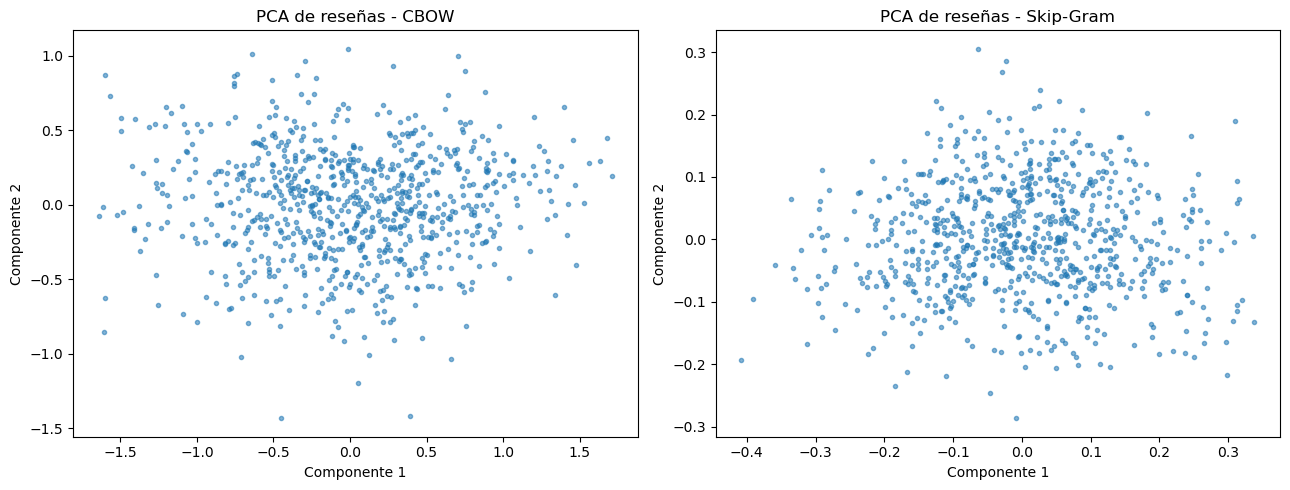

In [19]:
muestra=np.arange(min(800,len(df)))
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,(nombre,X) in zip(axes,[('CBOW',X_cbow),('Skip-Gram',X_sg)]):
    coords=PCA(n_components=2,random_state=42).fit_transform(X[muestra])
    ax.scatter(coords[:,0],coords[:,1],s=9,alpha=.55)
    ax.set(title=f'PCA de reseñas - {nombre}',xlabel='Componente 1',ylabel='Componente 2')
plt.tight_layout();plt.show()

In [20]:
from IPython.display import Markdown, display
for nombre,X in [('CBOW',X_cbow),('Skip-Gram',X_sg)]:
    pca = PCA(n_components=2,random_state=42).fit(X[muestra])
    v = pca.explained_variance_ratio_
    display(Markdown(f'**Interpretación — PCA {nombre}:** Los dos ejes visualizados explican **{v.sum():.1%}** de la variación de los vectores de la muestra (**{v[0]:.1%}** y **{v[1]:.1%}**, respectivamente). Los puntos cercanos representan reseñas próximas en esta proyección, pero la reducción a dos dimensiones pierde información. No es válido afirmar que existen grupos semánticos o categorías claramente separadas sin una evaluación adicional.'))

**Interpretación — PCA CBOW:** Los dos ejes visualizados explican **41.7%** de la variación de los vectores de la muestra (**30.8%** y **10.9%**, respectivamente). Los puntos cercanos representan reseñas próximas en esta proyección, pero la reducción a dos dimensiones pierde información. No es válido afirmar que existen grupos semánticos o categorías claramente separadas sin una evaluación adicional.

**Interpretación — PCA Skip-Gram:** Los dos ejes visualizados explican **30.4%** de la variación de los vectores de la muestra (**20.8%** y **9.5%**, respectivamente). Los puntos cercanos representan reseñas próximas en esta proyección, pero la reducción a dos dimensiones pierde información. No es válido afirmar que existen grupos semánticos o categorías claramente separadas sin una evaluación adicional.

## 14. Similitud entre reseñas
Se busca qué reseñas tienen vectores más parecidos a una reseña de referencia. Esto **no implica** que sean idénticas o que expresen exactamente la misma opinión.

In [21]:
def reseñas_similares(X, indice=0, n=5):
    simil=cosine_similarity(X[indice:indice+1],X).ravel()
    simil[indice]=-np.inf
    indices=np.argsort(simil)[-n:][::-1]
    return pd.DataFrame({'id_resena':df.iloc[indices].id_resena.to_numpy(),
                         'titulo_obra':df.iloc[indices].titulo_obra.to_numpy(),
                         'polaridad':df.iloc[indices].polaridad.to_numpy(),
                         'similitud_coseno':np.round(simil[indices],4)})
print('Reseña consultada:',df.iloc[0].id_resena,'-',df.iloc[0].titulo_obra)
print('CBOW:');display(reseñas_similares(X_cbow))
print('Skip-Gram:');display(reseñas_similares(X_sg))

Reseña consultada: p1_1 - nan
CBOW:


,id_resena,titulo_obra,polaridad,similitud_coseno
0,filmaffinity_16017176,La vida es bella,positiva,0.9672
1,p1_4724,NaN,negativa,0.9671
2,p1_2367,NaN,positiva,0.9669
3,p1_2340,NaN,positiva,0.9667
4,p1_4534,NaN,positiva,0.9651


Skip-Gram:


,id_resena,titulo_obra,polaridad,similitud_coseno
0,p1_2340,NaN,positiva,0.9845
1,filmaffinity_17242401,La vida es bella,positiva,0.9841
2,p1_850,NaN,positiva,0.9837
3,p1_1281,NaN,positiva,0.9834
4,p1_4724,NaN,negativa,0.9831


## 15. Comparación de similitud con TF-IDF
Se contrastan las reseñas más próximas en el espacio TF-IDF y en los vectores Word2Vec. TF-IDF depende de coincidencias de términos; Word2Vec puede captar patrones distribucionales aprendidos.

In [22]:
sim_tfidf=cosine_similarity(tfidf[0],tfidf).ravel();sim_tfidf[0]=-np.inf
indices=np.argsort(sim_tfidf)[-5:][::-1]
display(pd.DataFrame({'id_resena':df.iloc[indices].id_resena.to_numpy(),
                      'titulo_obra':df.iloc[indices].titulo_obra.to_numpy(),
                      'similitud_tfidf':np.round(sim_tfidf[indices],4)}))

,id_resena,titulo_obra,similitud_tfidf
0,sensacine_1008363799,It: Capítulo 2,0.2727
1,sensacine_1028241468,Cars 2,0.2718
2,sensacine_1040650752,Monster House,0.2699
3,sensacine_1008368317,Cars,0.2659
4,p1_2818,NaN,0.2640


Ambos modelos identificaron reseñas con alta similitud semántica, superior a 0.96.
Skip-Gram presentó valores más altos que CBOW, aunque ambos recuperaron reseñas de diferentes polaridades.
Esto demuestra que la similitud semántica no necesariamente implica opiniones iguales.

## 16. Resumen de métodos
| Método | Representación | Ventaja | Limitación |
|---|---|---|---|
| BoW | Frecuencia de palabras | Simple e interpretable | No considera contexto ni orden |
| TF-IDF | Peso relativo de términos | Destaca términos distintivos | No aprende significado contextual |
| CBOW | Vectores distribucionales | Aprovecha el contexto para aprender asociaciones | Puede suavizar patrones poco frecuentes |
| Skip-Gram | Vectores distribucionales | Aprende relaciones a partir de palabras centrales | Requiere entrenamiento y ajuste |

Las diferencias observadas dependen de los datos, la tokenización y los hiperparámetros.

## 17. Interpretación y conclusiones
1. Las 12.368 reseñas permiten estudiar patrones de frecuencia, importancia léxica y cercanía vectorial.
2. La validación de `id_resena` asegura la trazabilidad de las representaciones.
3. BoW y TF-IDF son bases útiles para interpretar el vocabulario, pero no modelan relaciones semánticas de manera explícita.
4. CBOW y Skip-Gram permiten comparar asociaciones entre palabras y similitudes entre documentos.
5. PCA es una herramienta visual exploratoria; no demuestra por sí sola superioridad de un modelo.
6. Para afirmar cuál modelo es mejor, se necesitaría una evaluación adicional con una tarea y métricas definidas, por ejemplo clasificación de polaridad sobre datos de prueba.

